In [24]:
import os
from pathlib import Path


DATASET_ROOT = 'D:\\Research\\rice' 

# Verify dataset exists and show structure
print("="*60)
print("DATASET VERIFICATION")
print("="*60)
print(f"\nDataset root: {os.path.abspath(DATASET_ROOT)}")

if not os.path.exists(DATASET_ROOT):
    print(f"\n ERROR: Dataset not found at {DATASET_ROOT}")
    print("Please update DATASET_ROOT variable with correct path!")
else:
    print("\n Dataset found!")
    print("\nTrain folder contents:")
    train_contents = os.listdir(f"{DATASET_ROOT}/train")
    for item in train_contents:
        count = len(os.listdir(f"{DATASET_ROOT}/train/{item}"))
        print(f"  - {item}: {count} images")
    
    print("\nTest folder contents:")
    test_contents = os.listdir(f"{DATASET_ROOT}/test")
    for item in test_contents:
        count = len(os.listdir(f"{DATASET_ROOT}/test/{item}"))
        print(f"  - {item}: {count} images")


DATASET VERIFICATION

Dataset root: D:\Research\rice

 Dataset found!

Train folder contents:
  - Healthy: 18000 images
  - Mold: 1350 images

Test folder contents:
  - Healthy: 2000 images
  - Mold: 150 images


# Import Dependencies

In [25]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import json

print("\n All dependencies imported successfully!")


 All dependencies imported successfully!


# CV based re-categorization functions

In [26]:
def convert_to_hsv(image_path):
    """
    Convert RGB image to HSV color space.
    HSV separates color (Hue) from brightness (Value), making mold detection easier.
    """
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image: {image_path}")
    
    # OpenCV reads as BGR, convert to RGB then HSV
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return img_rgb, hsv

In [27]:
def detect_mold_regions(hsv_image):
    """
    Detect mold regions using HSV color thresholds - BALANCED VERSION.
    
    Mold characteristics (more balanced):
    - Hue: 15-50° (wider range to catch brownish mold)
    - Saturation: 60-255 (lower saturation to catch faded mold)
    - Value: 20-140 (slightly wider range for different lighting)
    """
    # More balanced mold color range in HSV
    lower_mold = np.array([15, 60, 20])   # More sensitive lower bound
    upper_mold = np.array([50, 255, 140])  # More sensitive upper bound
    
    # Create binary mask (255 = mold, 0 = not mold)
    mask = cv2.inRange(hsv_image, lower_mold, upper_mold)
    return mask

In [28]:
def apply_morphology(mask):
    """
    Clean up the mold mask using morphological operations and area filtering.
    """
    # Create kernels
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    
    # Apply opening (erosion followed by dilation) - removes noise
    mask_clean = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    
    # Apply closing (dilation followed by erosion) - fills gaps
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel_close)
    
    # Remove small connected components (noise)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    
    # Filter out small areas (reduced to 50 pixels to catch smaller mold spots)
    min_area = 50
    filtered_mask = np.zeros_like(mask_clean)
    
    for i in range(1, num_labels):  # Skip background (label 0)
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            filtered_mask[labels == i] = 255
    
    return filtered_mask

In [29]:
def segment_grain_region(img_rgb):
    """
    Separate grain from background using Otsu's thresholding.
    This helps calculate accurate mold coverage percentage.
    """
    # Convert to grayscale
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    
    # Apply Otsu's thresholding (automatically finds optimal threshold)
    _, grain_mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    return grain_mask

In [30]:
def calculate_mold_coverage(image_path, visualize=False):
    """
    Main function: Calculate mold coverage percentage and classify severity.
    
    Returns:
        coverage_pct: Percentage of grain covered by mold (0-100)
        severity: 'early-risk' or 'spoiled'
        debug_info: Dictionary with intermediate results (if visualize=True)
    """
    try:
        # Step 1: Load and convert to HSV
        img_rgb, hsv = convert_to_hsv(image_path)
        
        # Step 2: Detect mold regions
        mold_mask = detect_mold_regions(hsv)
        
        # Step 3: Clean up mold mask
        mold_mask_clean = apply_morphology(mold_mask)
        
        # Step 4: Segment grain region
        grain_mask = segment_grain_region(img_rgb)
        
        # Step 5: Calculate coverage percentage
        grain_pixels = np.sum(grain_mask > 0)
        
        if grain_pixels == 0:
            return 0.0, "early-risk", None
        
        # Mold pixels within grain region only
        mold_in_grain = np.sum((mold_mask_clean > 0) & (grain_mask > 0))
        coverage_pct = (mold_in_grain / grain_pixels) * 100
        
        # Step 6: Classify severity based on coverage - BINARY CLASSIFICATION
        # Since all images are from 'mold' folder:
        # - early-risk: < 15% coverage (light contamination, still edible with processing)
        # - spoiled: >= 15% coverage (significant contamination, not suitable for consumption)
        if coverage_pct < 10:
            severity = "early-risk"
        else:
            severity = "spoiled"
        
        # Debug info for visualization
        debug_info = None
        if visualize:
            debug_info = {
                'original': img_rgb,
                'hsv': hsv,
                'mold_mask': mold_mask,
                'mold_mask_clean': mold_mask_clean,
                'grain_mask': grain_mask,
                'overlay': create_overlay(img_rgb, mold_mask_clean)
            }
        
        return coverage_pct, severity, debug_info
    
    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return None, None, None

In [31]:
def create_overlay(img_rgb, mold_mask):
    """Create visualization with mold regions highlighted in red."""
    overlay = img_rgb.copy()
    overlay[mold_mask > 0] = [255, 0, 0]  # Red overlay on mold
    return cv2.addWeighted(img_rgb, 0.7, overlay, 0.3, 0)


print("Re-categorization functions defined successfully!")


Re-categorization functions defined successfully!


# Visualize algorithms on sample images


TESTING ALGORITHM ON SAMPLE IMAGES

Processing: Grainset_rice_2020-02-13-08-56-30_1_p600s.png


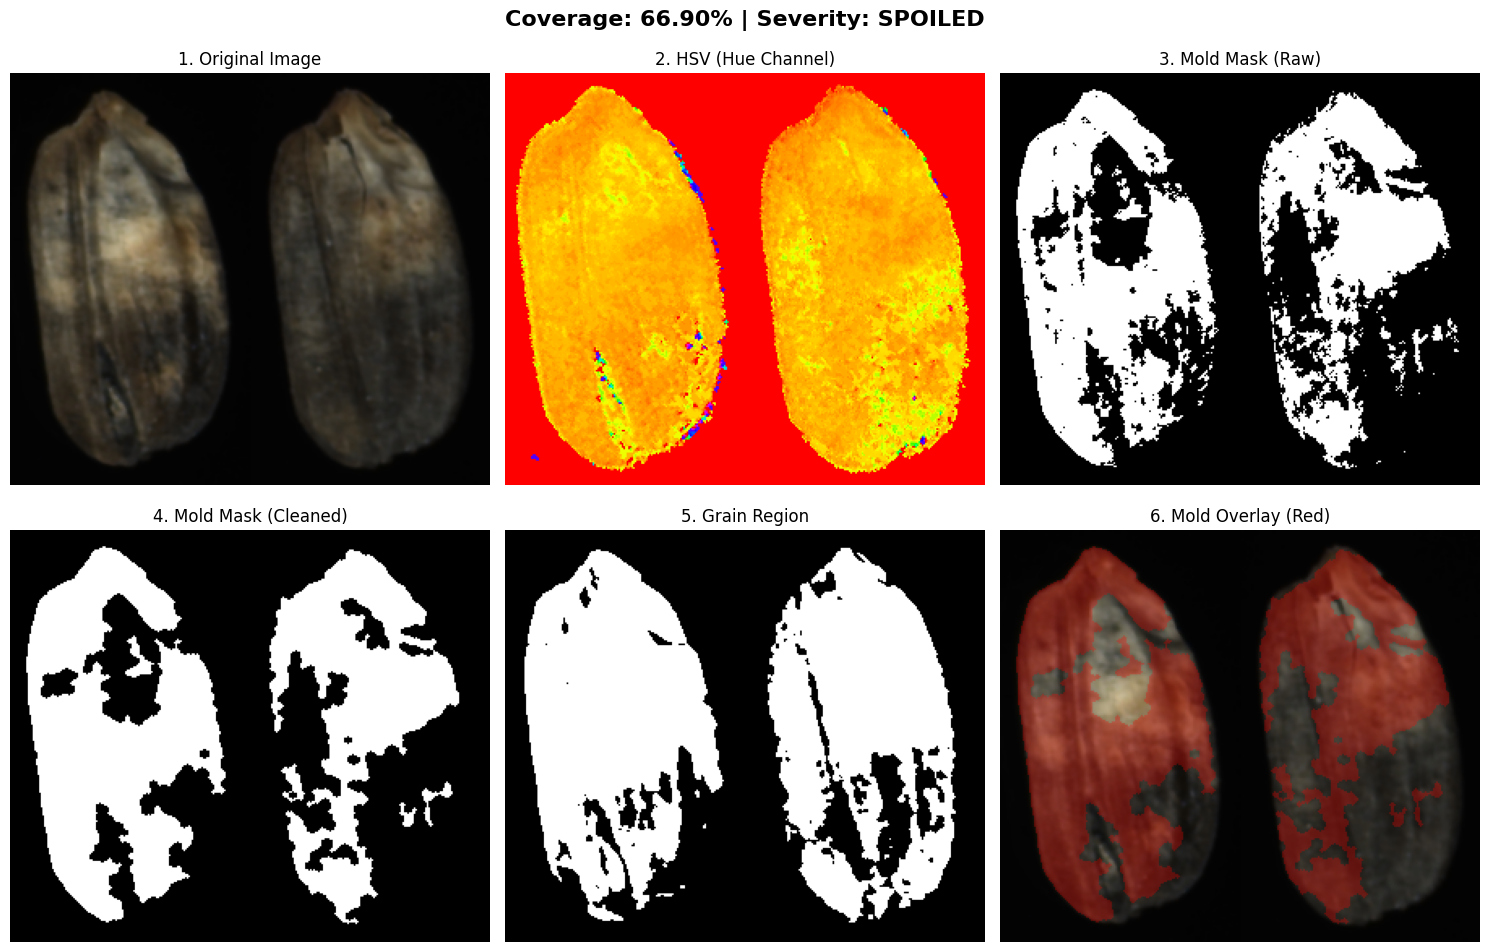


Processing: Grainset_rice_2020-02-13-15-23-05_0_p600s.png


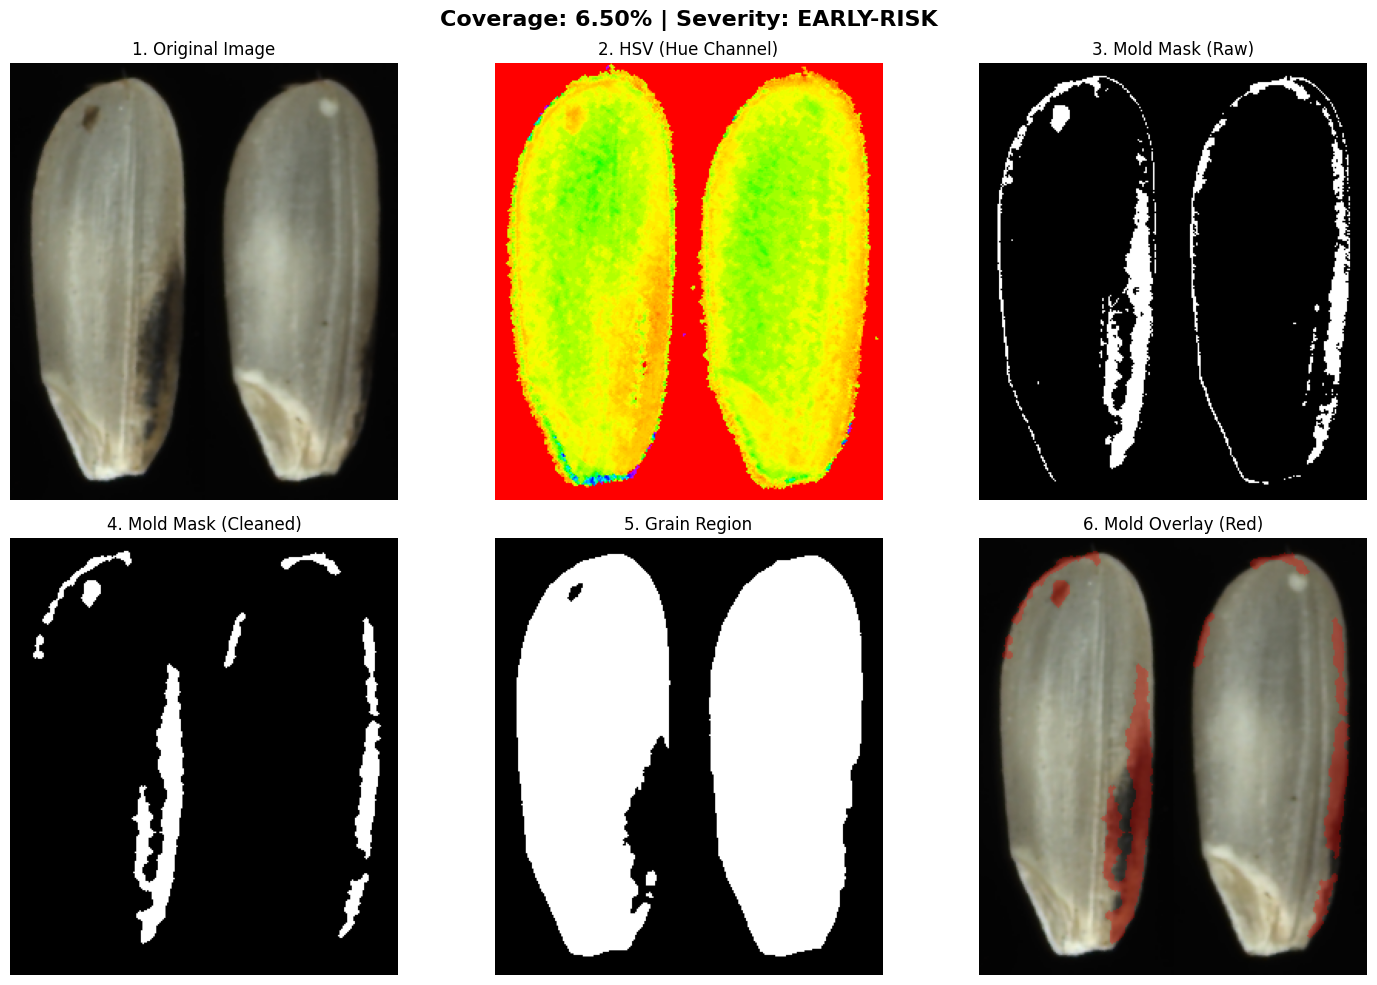


Processing: Grainset_rice_2020-02-13-17-40-19_4_p600s.png


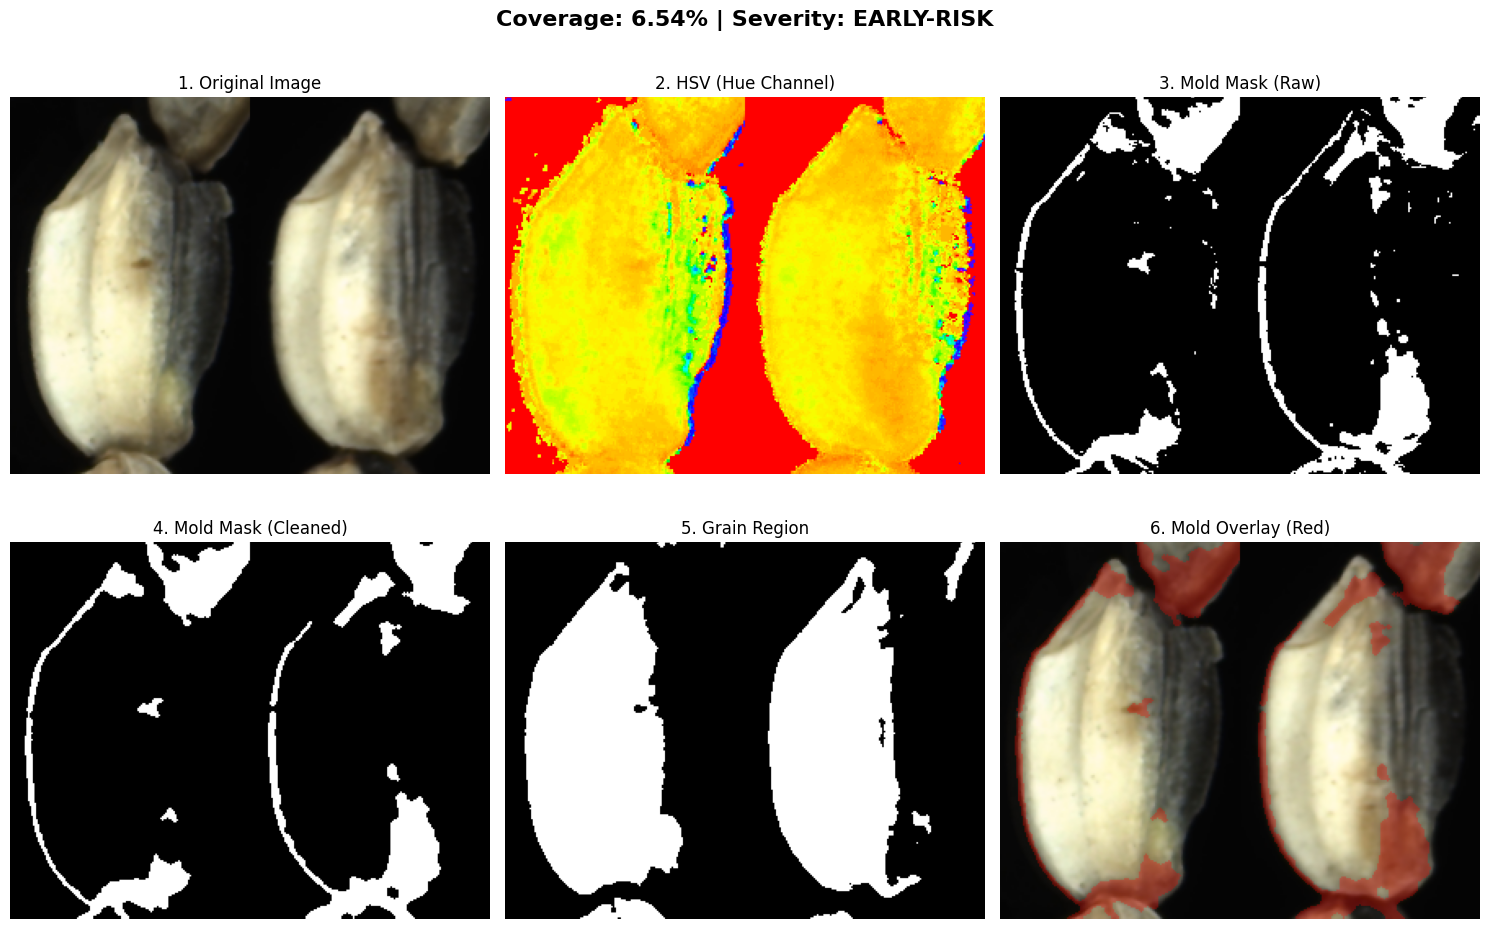

In [32]:

def visualize_sample_processing(image_path):
    """
    Visualize the re-categorization process step-by-step.
    Use this to verify the algorithm works correctly.
    """
    coverage, severity, debug = calculate_mold_coverage(image_path, visualize=True)
    
    if debug is None:
        print(f"Failed to process {image_path}")
        return
    
    # Create figure with subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'Coverage: {coverage:.2f}% | Severity: {severity.upper()}', 
                 fontsize=16, fontweight='bold')
    
    # Original image
    axes[0, 0].imshow(debug['original'])
    axes[0, 0].set_title('1. Original Image')
    axes[0, 0].axis('off')
    
    # HSV image (showing Hue channel)
    axes[0, 1].imshow(debug['hsv'][:, :, 0], cmap='hsv')
    axes[0, 1].set_title('2. HSV (Hue Channel)')
    axes[0, 1].axis('off')
    
    # Raw mold mask
    axes[0, 2].imshow(debug['mold_mask'], cmap='gray')
    axes[0, 2].set_title('3. Mold Mask (Raw)')
    axes[0, 2].axis('off')
    
    # Cleaned mold mask
    axes[1, 0].imshow(debug['mold_mask_clean'], cmap='gray')
    axes[1, 0].set_title('4. Mold Mask (Cleaned)')
    axes[1, 0].axis('off')
    
    # Grain segmentation
    axes[1, 1].imshow(debug['grain_mask'], cmap='gray')
    axes[1, 1].set_title('5. Grain Region')
    axes[1, 1].axis('off')
    
    # Final overlay
    axes[1, 2].imshow(debug['overlay'])
    axes[1, 2].set_title('6. Mold Overlay (Red)')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.show()


# Test on sample images
print("\n" + "="*60)
print("TESTING ALGORITHM ON SAMPLE IMAGES")
print("="*60)

train_mold_dir = Path(f"{DATASET_ROOT}/train/mold")

if train_mold_dir.exists():
    # Get first 3 mold images for testing
    sample_images = list(train_mold_dir.glob("*.jpg"))[:3]
    
    if not sample_images:
        sample_images = list(train_mold_dir.glob("*.png"))[:3]
    
    if sample_images:
        for img_path in sample_images:
            print(f"\nProcessing: {img_path.name}")
            visualize_sample_processing(str(img_path))
    else:
        print("No sample images found. Check if images are .jpg or .png format")
else:
    print(f"Mold directory not found: {train_mold_dir}")

# Batch Process All Mold Images

In [33]:
def process_mold_dataset(mold_dir, output_csv, dataset_type="train"):
    """
    Process all mold images and save results to CSV.
    
    Args:
        mold_dir: Path to mold images folder
        output_csv: Output CSV path for results
        dataset_type: "train" or "test"
    """
    print(f"\n{'='*60}")
    print(f"PROCESSING {dataset_type.upper()} MOLD IMAGES")
    print(f"{'='*60}")
    
    mold_dir = Path(mold_dir)
    
    if not mold_dir.exists():
        print(f"ERROR: Directory not found: {mold_dir}")
        return None
    
    # Find all image files (jpg and png)
    image_files = list(mold_dir.glob("*.jpg")) + list(mold_dir.glob("*.png"))
    
    if not image_files:
        print(f"⚠️ WARNING: No images found in {mold_dir}")
        return None
    
    print(f"Found {len(image_files)} images in {mold_dir}")
    
    results = []
    failed = []
    
    # Process each image with progress bar
    for img_path in tqdm(image_files, desc=f"Processing {dataset_type}"):
        coverage, severity, _ = calculate_mold_coverage(img_path)
        
        if coverage is not None:
            results.append({
                'filename': img_path.name,
                'original_path': str(img_path.absolute()),
                'original_label': 'mold',
                'coverage_pct': round(coverage, 2),
                'new_severity': severity,
                'dataset': dataset_type
            })
        else:
            failed.append(img_path.name)
    
    # Save results
    df = pd.DataFrame(results)
    
    # Create output directory if it doesn't exist
    os.makedirs(os.path.dirname(output_csv), exist_ok=True)
    df.to_csv(output_csv, index=False)
    
    # Print statistics
    print(f"\n Successfully processed: {len(results)} images")
    print(f"Failed: {len(failed)} images")
    
    if failed:
        print("\nFailed images:")
        for f in failed[:10]:  # Show first 10
            print(f"  - {f}")
    
    # Show severity distribution
    print("\n Severity Distribution:")
    severity_counts = df['new_severity'].value_counts()
    for severity, count in severity_counts.items():
        pct = (count / len(df)) * 100
        print(f"  {severity:12s}: {count:4d} images ({pct:.1f}%)")
    
    # Show coverage statistics
    print("\n Coverage Statistics:")
    print(df.groupby('new_severity')['coverage_pct'].describe())
    
    return df


# Create processed directory
processed_dir = f"{DATASET_ROOT}/processed"
os.makedirs(processed_dir, exist_ok=True)

# Process TRAIN mold images
print("\n" + "="*60)
print("STARTING TRAIN SET PROCESSING")
print("="*60)

train_output = f"{processed_dir}/train_recategorized.csv"
df_train = process_mold_dataset(
    mold_dir=f"{DATASET_ROOT}/train/mold",
    output_csv=train_output,
    dataset_type="train"
)

# Process TEST mold images
print("\n" + "="*60)
print("STARTING TEST SET PROCESSING")
print("="*60)

test_output = f"{processed_dir}/test_recategorized.csv"
df_test = process_mold_dataset(
    mold_dir=f"{DATASET_ROOT}/test/mold",
    output_csv=test_output,
    dataset_type="test"
)


STARTING TRAIN SET PROCESSING

PROCESSING TRAIN MOLD IMAGES
Found 1350 images in D:\Research\rice\train\mold


Processing train: 100%|██████████| 1350/1350 [00:04<00:00, 326.34it/s]



 Successfully processed: 1350 images
Failed: 0 images

 Severity Distribution:
  spoiled     : 1220 images (90.4%)
  early-risk  :  130 images (9.6%)

 Coverage Statistics:
               count       mean        std    min      25%    50%      75%  \
new_severity                                                                 
early-risk     130.0   5.778000   2.456976   0.05   3.9875   5.90   7.7200   
spoiled       1220.0  46.255795  23.200943  10.09  26.4050  43.77  64.8825   

                max  
new_severity         
early-risk     9.99  
spoiled       98.40  

STARTING TEST SET PROCESSING

PROCESSING TEST MOLD IMAGES
Found 150 images in D:\Research\rice\test\mold


Processing test: 100%|██████████| 150/150 [00:04<00:00, 32.95it/s]


 Successfully processed: 150 images
Failed: 0 images

 Severity Distribution:
  spoiled     :  137 images (91.3%)
  early-risk  :   13 images (8.7%)

 Coverage Statistics:
              count       mean        std    min    25%    50%    75%    max
new_severity                                                                
early-risk     13.0   6.372308   2.426091   2.27   4.39   6.27   8.60   9.58
spoiled       137.0  47.711460  22.585435  10.12  30.16  44.86  64.32  94.80


# Visualization and Statistics


GENERATING VISUALIZATIONS
✅ Saved: D:\Research\rice/processed/severity_distribution.png


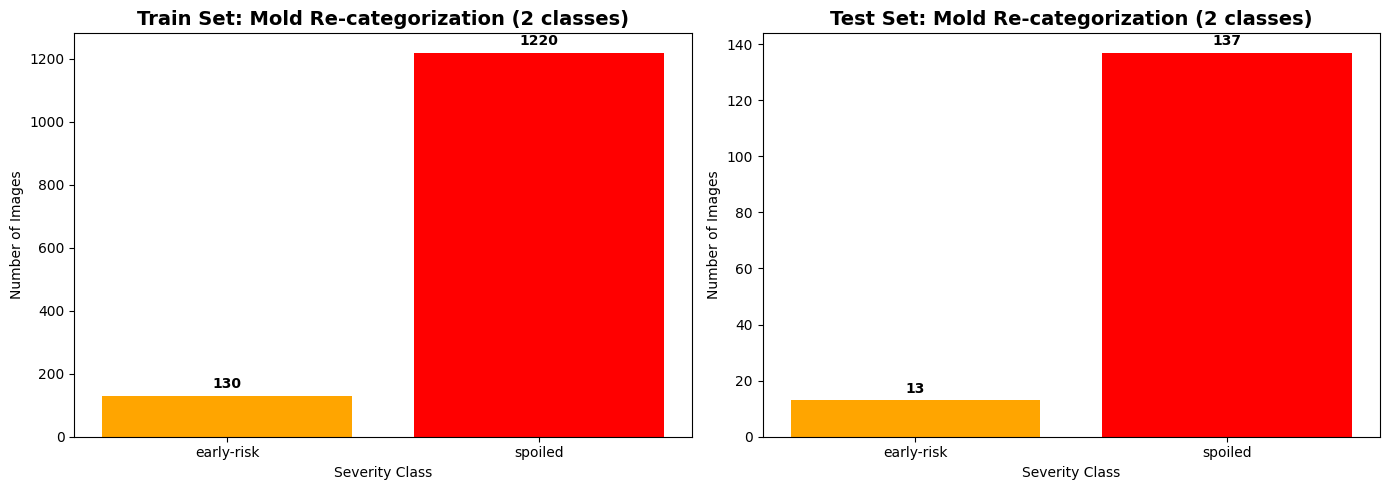

✅ Saved: D:\Research\rice/processed/coverage_histogram.png


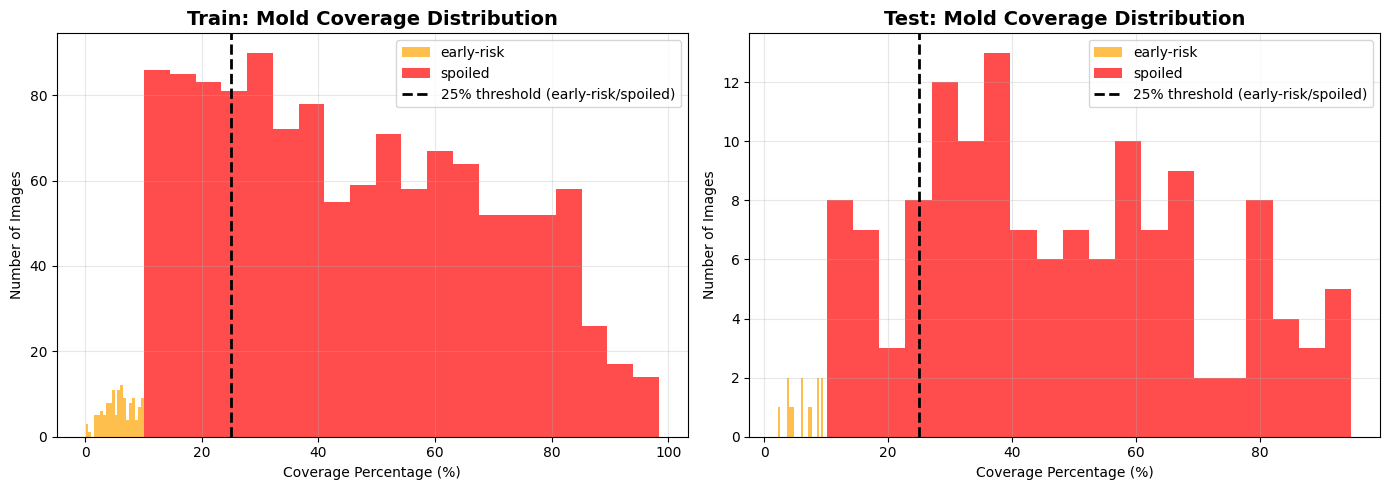

In [34]:
def plot_severity_distribution(df_train, df_test):
    """Plot severity distribution for train and test sets (only early-risk and spoiled)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Train distribution
    train_counts = df_train['new_severity'].value_counts().reindex(['early-risk', 'spoiled'], fill_value=0)
    colors = ['orange', 'red']
    
    axes[0].bar(train_counts.index, train_counts.values, color=colors)
    axes[0].set_title('Train Set: Mold Re-categorization (2 classes)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Number of Images')
    axes[0].set_xlabel('Severity Class')
    for i, v in enumerate(train_counts.values):
        axes[0].text(i, v + max(train_counts.values)*0.02, str(v), ha='center', fontweight='bold')
    
    # Test distribution
    test_counts = df_test['new_severity'].value_counts().reindex(['early-risk', 'spoiled'], fill_value=0)
    
    axes[1].bar(test_counts.index, test_counts.values, color=colors)
    axes[1].set_title('Test Set: Mold Re-categorization (2 classes)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Number of Images')
    axes[1].set_xlabel('Severity Class')
    for i, v in enumerate(test_counts.values):
        axes[1].text(i, v + max(test_counts.values)*0.02, str(v), ha='center', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{processed_dir}/severity_distribution.png", dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {processed_dir}/severity_distribution.png")
    plt.show()


def plot_coverage_histograms(df_train, df_test):
    """Plot coverage percentage distributions."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Train coverage distribution
    for severity, color in [('early-risk', 'orange'), ('spoiled', 'red')]:
        data = df_train[df_train['new_severity'] == severity]['coverage_pct']
        if len(data) > 0:
            axes[0].hist(data, bins=20, alpha=0.7, label=severity, color=color)
    
    axes[0].axvline(x=25, color='black', linestyle='--', linewidth=2, label='25% threshold (early-risk/spoiled)')
    axes[0].set_title('Train: Mold Coverage Distribution', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Coverage Percentage (%)')
    axes[0].set_ylabel('Number of Images')
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    
    # Test coverage distribution
    for severity, color in [('early-risk', 'orange'), ('spoiled', 'red')]:
        data = df_test[df_test['new_severity'] == severity]['coverage_pct']
        if len(data) > 0:
            axes[1].hist(data, bins=20, alpha=0.7, label=severity, color=color)
    
    axes[1].axvline(x=25, color='black', linestyle='--', linewidth=2, label='25% threshold (early-risk/spoiled)')
    axes[1].set_title('Test: Mold Coverage Distribution', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Coverage Percentage (%)')
    axes[1].set_ylabel('Number of Images')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{processed_dir}/coverage_histogram.png", dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {processed_dir}/coverage_histogram.png")
    plt.show()


# Generate visualizations
if df_train is not None and df_test is not None:
    print("\n" + "="*60)
    print("GENERATING VISUALIZATIONS")
    print("="*60)
    
    plot_severity_distribution(df_train, df_test)
    plot_coverage_histograms(df_train, df_test)

In [35]:
# Analyze coverage distribution in more detail
if df_train is not None:
    print("\n" + "="*60)
    print("DETAILED COVERAGE ANALYSIS")
    print("="*60)
    
    # Show coverage statistics
    print(f"\nTotal images processed: {len(df_train)}")
    print(f"Early-risk: {len(df_train[df_train['new_severity'] == 'early-risk'])}")
    print(f"Spoiled: {len(df_train[df_train['new_severity'] == 'spoiled'])}")
    
    # Show coverage ranges
    early_risk_coverage = df_train[df_train['new_severity'] == 'early-risk']['coverage_pct']
    spoiled_coverage = df_train[df_train['new_severity'] == 'spoiled']['coverage_pct']
    
    print(f"\nEarly-risk coverage range: {early_risk_coverage.min():.2f}% - {early_risk_coverage.max():.2f}%")
    print(f"Spoiled coverage range: {spoiled_coverage.min():.2f}% - {spoiled_coverage.max():.2f}%")
    
    # Show images close to threshold (8-12% range)
    threshold_range = df_train[(df_train['coverage_pct'] >= 8) & (df_train['coverage_pct'] <= 12)]
    print(f"\nImages near 10% threshold (8-12% range): {len(threshold_range)}")
    if len(threshold_range) > 0:
        print("Sample filenames in threshold range:")
        for idx, row in threshold_range.head(5).iterrows():
            print(f"  {row['filename']}: {row['coverage_pct']}% - {row['new_severity']}")


DETAILED COVERAGE ANALYSIS

Total images processed: 1350
Early-risk: 130
Spoiled: 1220

Early-risk coverage range: 0.05% - 9.99%
Spoiled coverage range: 10.09% - 98.40%

Images near 10% threshold (8-12% range): 66
Sample filenames in threshold range:
  Grainset_rice_2020-02-26-21-27-09_5_p600s.png: 8.22% - early-risk
  Grainset_rice_2020-03-14-15-03-59_3_p600s.png: 10.3% - spoiled
  Grainset_rice_2020-03-28-21-41-09_4_p600s.png: 10.09% - spoiled
  Grainset_rice_2020-04-14-14-42-48_2_p600s.png: 11.28% - spoiled
  Grainset_rice_2020-04-19-13-31-43_3_p600s.png: 8.42% - early-risk


In [36]:
"""
COMPREHENSIVE VALIDATION TOOL
==============================
Verify that mold images are correctly classified as early-risk or spoiled
with accurate mold coverage percentages.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from tqdm import tqdm
import seaborn as sns

# ============================================
# CONFIGURATION
# ============================================

DATASET_ROOT = './rice_dataset'
PROCESSED_DIR = f'{DATASET_ROOT}/processed'

# Load results
df_train = pd.read_csv(f'{PROCESSED_DIR}/train_recategorized.csv')
df_test = pd.read_csv(f'{PROCESSED_DIR}/test_recategorized.csv')

print("="*70)
print("COMPREHENSIVE VALIDATION OF MOLD CLASSIFICATIONS")
print("="*70)

# ============================================
# VALIDATION 1: STATISTICAL SANITY CHECKS
# ============================================

print("\n" + "="*70)
print("VALIDATION 1: STATISTICAL SANITY CHECKS")
print("="*70)

def statistical_checks(df, dataset_name="train"):
    """Perform automated statistical checks."""
    print(f"\n{dataset_name.upper()} SET:")
    
    checks_passed = 0
    total_checks = 0
    
    # Check 1: All early-risk should have coverage < threshold
    threshold = 10  # Your current threshold
    total_checks += 1
    early_wrong = df[(df['new_severity'] == 'early-risk') & (df['coverage_pct'] >= threshold)]
    if len(early_wrong) == 0:
        print(f"  ✅ Check 1: All early-risk images have coverage < {threshold}%")
        checks_passed += 1
    else:
        print(f"  ❌ Check 1: {len(early_wrong)} early-risk images have coverage >= {threshold}%")
        print(f"     These images are MISCLASSIFIED!")
    
    # Check 2: All spoiled should have coverage >= threshold
    total_checks += 1
    spoiled_wrong = df[(df['new_severity'] == 'spoiled') & (df['coverage_pct'] < threshold)]
    if len(spoiled_wrong) == 0:
        print(f"  ✅ Check 2: All spoiled images have coverage >= {threshold}%")
        checks_passed += 1
    else:
        print(f"  ❌ Check 2: {len(spoiled_wrong)} spoiled images have coverage < {threshold}%")
        print(f"     These images are MISCLASSIFIED!")
    
    # Check 3: No negative coverage
    total_checks += 1
    negative = df[df['coverage_pct'] < 0]
    if len(negative) == 0:
        print(f"  ✅ Check 3: No negative coverage values")
        checks_passed += 1
    else:
        print(f"  ❌ Check 3: {len(negative)} images have NEGATIVE coverage!")
    
    # Check 4: No coverage > 100%
    total_checks += 1
    over_100 = df[df['coverage_pct'] > 100]
    if len(over_100) == 0:
        print(f"  ✅ Check 4: No coverage values > 100%")
        checks_passed += 1
    else:
        print(f"  ❌ Check 4: {len(over_100)} images have coverage > 100%!")
    
    # Check 5: Coverage distribution makes sense
    total_checks += 1
    early_mean = df[df['new_severity'] == 'early-risk']['coverage_pct'].mean()
    spoiled_mean = df[df['new_severity'] == 'spoiled']['coverage_pct'].mean()
    
    if spoiled_mean > early_mean:
        print(f"  ✅ Check 5: Spoiled avg ({spoiled_mean:.1f}%) > Early-risk avg ({early_mean:.1f}%)")
        checks_passed += 1
    else:
        print(f"  ❌ Check 5: Spoiled avg ({spoiled_mean:.1f}%) <= Early-risk avg ({early_mean:.1f}%)")
    
    # Check 6: No duplicate filenames
    total_checks += 1
    duplicates = df[df.duplicated(subset=['filename'], keep=False)]
    if len(duplicates) == 0:
        print(f"  ✅ Check 6: No duplicate filenames")
        checks_passed += 1
    else:
        print(f"  ❌ Check 6: {len(duplicates)} duplicate filenames found!")
    
    print(f"\n  SCORE: {checks_passed}/{total_checks} checks passed")
    return checks_passed == total_checks

train_pass = statistical_checks(df_train, "train")
test_pass = statistical_checks(df_test, "test")

if train_pass and test_pass:
    print("\n✅ All statistical checks PASSED!")
else:
    print("\n⚠️  Some statistical checks FAILED - review results above")


# ============================================
# VALIDATION 2: VISUAL GRID INSPECTION
# ============================================

print("\n" + "="*70)
print("VALIDATION 2: VISUAL GRID INSPECTION")
print("="*70)

def create_visual_grid(df, dataset_name="train", samples_per_range=10):
    """
    Create visual grids showing images at different coverage percentages.
    This helps you verify if classifications visually match the coverage.
    """
    
    # Define coverage ranges
    ranges = [
        (0, 5, "0-5%", "Very light mold"),
        (5, 10, "5-10%", "Light mold (near threshold)"),
        (10, 15, "10-15%", "Just above threshold"),
        (15, 25, "15-25%", "Moderate mold"),
        (25, 40, "25-40%", "Heavy mold"),
        (40, 100, "40-100%", "Very heavy mold")
    ]
    
    for min_cov, max_cov, label, description in ranges:
        samples = df[(df['coverage_pct'] >= min_cov) & (df['coverage_pct'] < max_cov)]
        
        if len(samples) == 0:
            print(f"\n  ⚠️ No images in range {label}")
            continue
        
        print(f"\n  Processing range: {label} ({len(samples)} images)")
        
        # Sample images
        n_samples = min(samples_per_range, len(samples))
        sample_imgs = samples.sample(n_samples, random_state=42)
        
        # Create grid
        cols = 5
        rows = (n_samples + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
        
        # Make axes 2D array even if only 1 row
        if rows == 1:
            axes = axes.reshape(1, -1)
        
        fig.suptitle(f'{dataset_name.upper()}: Coverage {label} - {description}\n'
                     f'👀 Do these images visually match {label} mold coverage?',
                     fontsize=16, fontweight='bold', y=0.98)
        
        for idx, (_, row) in enumerate(sample_imgs.iterrows()):
            i, j = idx // cols, idx % cols
            
            # Load image
            img = cv2.imread(row['original_path'])
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                axes[i, j].imshow(img_rgb)
                
                # Color code by classification
                color = 'orange' if row['new_severity'] == 'early-risk' else 'red'
                border_color = 'green' if min_cov < 10 else 'orange' if max_cov <= 25 else 'red'
                
                axes[i, j].set_title(
                    f"{row['coverage_pct']:.1f}%\n{row['new_severity']}\n{Path(row['filename']).stem[:15]}",
                    fontsize=10, 
                    fontweight='bold',
                    color=color,
                    bbox=dict(boxstyle='round', facecolor=border_color, alpha=0.2)
                )
                axes[i, j].axis('off')
            else:
                axes[i, j].text(0.5, 0.5, 'Image\nNot Found', 
                              ha='center', va='center')
                axes[i, j].axis('off')
        
        # Hide empty subplots
        for idx in range(n_samples, rows * cols):
            i, j = idx // cols, idx % cols
            axes[i, j].axis('off')
        
        plt.tight_layout()
        filename = f'{PROCESSED_DIR}/visual_validation_{dataset_name}_{label.replace("%", "pct")}.png'
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"    ✅ Saved: {filename}")
        plt.show()

print("\n📸 Generating visual grids for train set...")
create_visual_grid(df_train, "train", samples_per_range=10)

print("\n📸 Generating visual grids for test set...")
create_visual_grid(df_test, "test", samples_per_range=6)


# ============================================
# VALIDATION 3: BOUNDARY CASE ANALYSIS
# ============================================

print("\n" + "="*70)
print("VALIDATION 3: BOUNDARY CASE ANALYSIS (Near Threshold)")
print("="*70)

def analyze_boundary_cases(df, threshold=10, margin=3, dataset_name="train"):
    """
    Focus on images near the classification boundary.
    These are most likely to be misclassified.
    """
    
    boundary = df[
        (df['coverage_pct'] >= threshold - margin) & 
        (df['coverage_pct'] <= threshold + margin)
    ].copy().sort_values('coverage_pct')
    
    print(f"\n{dataset_name.upper()}: Boundary Cases ({threshold-margin}% to {threshold+margin}%)")
    print(f"  Found {len(boundary)} images near threshold")
    
    if len(boundary) == 0:
        print("  ✅ No boundary cases - clear separation between classes")
        return
    
    # Show distribution across boundary
    print(f"\n  Distribution:")
    for severity in ['early-risk', 'spoiled']:
        count = len(boundary[boundary['new_severity'] == severity])
        pct = (count / len(boundary) * 100) if len(boundary) > 0 else 0
        print(f"    {severity:12s}: {count:3d} images ({pct:5.1f}%)")
    
    # Create detailed visualization
    n_display = min(20, len(boundary))
    boundary_sample = boundary.head(n_display)
    
    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    fig.suptitle(
        f'{dataset_name.upper()}: Boundary Cases Near {threshold}% Threshold\n'
        f'⚠️ CRITICAL: These images are most likely to be misclassified!\n'
        f'👀 Verify that images <{threshold}% look "early-risk" and >={threshold}% look "spoiled"',
        fontsize=14, fontweight='bold'
    )
    
    for idx, (_, row) in enumerate(boundary_sample.iterrows()):
        i, j = idx // 5, idx % 5
        
        img = cv2.imread(row['original_path'])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(img_rgb)
            
            # Highlight if exactly at threshold
            if abs(row['coverage_pct'] - threshold) < 0.5:
                border_style = dict(boxstyle='round', facecolor='yellow', 
                                  edgecolor='black', linewidth=3, alpha=0.8)
                title_prefix = "⚠️ "
            else:
                color = 'orange' if row['new_severity'] == 'early-risk' else 'red'
                border_style = dict(boxstyle='round', facecolor=color, alpha=0.3)
                title_prefix = ""
            
            axes[i, j].set_title(
                f"{title_prefix}{row['coverage_pct']:.2f}%\n{row['new_severity']}",
                fontsize=10,
                fontweight='bold',
                bbox=border_style
            )
            axes[i, j].axis('off')
    
    # Hide empty subplots
    for idx in range(n_display, 20):
        i, j = idx // 5, idx % 5
        axes[i, j].axis('off')
    
    plt.tight_layout()
    filename = f'{PROCESSED_DIR}/boundary_analysis_{dataset_name}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"\n  ✅ Saved: {filename}")
    plt.show()
    
    # List boundary cases for manual review
    print(f"\n  📋 Boundary Cases List (for manual review):")
    print(f"  {'Filename':<30s} {'Coverage':>10s} {'Classification':>15s}")
    print("  " + "-"*60)
    for _, row in boundary_sample.iterrows():
        print(f"  {Path(row['filename']).name:<30s} {row['coverage_pct']:>9.2f}% {row['new_severity']:>15s}")

analyze_boundary_cases(df_train, threshold=10, margin=3, dataset_name="train")
analyze_boundary_cases(df_test, threshold=10, margin=3, dataset_name="test")


# ============================================
# VALIDATION 4: EXTREME CASES CHECK
# ============================================

print("\n" + "="*70)
print("VALIDATION 4: EXTREME CASES CHECK")
print("="*70)

def check_extreme_cases(df, dataset_name="train"):
    """Check minimum and maximum coverage for each class."""
    
    print(f"\n{dataset_name.upper()}:")
    
    # Early-risk extremes
    early_risk = df[df['new_severity'] == 'early-risk']
    if len(early_risk) > 0:
        min_early = early_risk.nsmallest(5, 'coverage_pct')
        max_early = early_risk.nlargest(5, 'coverage_pct')
        
        print(f"\n  EARLY-RISK Class:")
        print(f"    Total: {len(early_risk)} images")
        print(f"    Range: {early_risk['coverage_pct'].min():.2f}% to {early_risk['coverage_pct'].max():.2f}%")
        print(f"    Mean: {early_risk['coverage_pct'].mean():.2f}%")
        
        print(f"\n    ⬇️  Lowest 5 coverage:")
        for _, row in min_early.iterrows():
            print(f"      {Path(row['filename']).name:<30s}: {row['coverage_pct']:>6.2f}%")
        
        print(f"\n    ⬆️  Highest 5 coverage (should be close to threshold):")
        for _, row in max_early.iterrows():
            status = "⚠️ " if row['coverage_pct'] >= 10 else "✅ "
            print(f"      {status}{Path(row['filename']).name:<30s}: {row['coverage_pct']:>6.2f}%")
    
    # Spoiled extremes
    spoiled = df[df['new_severity'] == 'spoiled']
    if len(spoiled) > 0:
        min_spoiled = spoiled.nsmallest(5, 'coverage_pct')
        max_spoiled = spoiled.nlargest(5, 'coverage_pct')
        
        print(f"\n  SPOILED Class:")
        print(f"    Total: {len(spoiled)} images")
        print(f"    Range: {spoiled['coverage_pct'].min():.2f}% to {spoiled['coverage_pct'].max():.2f}%")
        print(f"    Mean: {spoiled['coverage_pct'].mean():.2f}%")
        
        print(f"\n    ⬇️  Lowest 5 coverage (should be close to threshold):")
        for _, row in min_spoiled.iterrows():
            status = "⚠️ " if row['coverage_pct'] < 10 else "✅ "
            print(f"      {status}{Path(row['filename']).name:<30s}: {row['coverage_pct']:>6.2f}%")
        
        print(f"\n    ⬆️  Highest 5 coverage:")
        for _, row in max_spoiled.iterrows():
            print(f"      {Path(row['filename']).name:<30s}: {row['coverage_pct']:>6.2f}%")
    
    # Visualize extremes
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    fig.suptitle(f'{dataset_name.upper()}: Extreme Cases', fontsize=14, fontweight='bold')
    
    # Plot lowest early-risk
    for idx, (_, row) in enumerate(min_early.iterrows()):
        img = cv2.imread(row['original_path'])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[0, idx].imshow(img_rgb)
            axes[0, idx].set_title(f"Early-risk\n{row['coverage_pct']:.2f}%\n(Lowest)", 
                                  fontsize=9, color='orange', fontweight='bold')
            axes[0, idx].axis('off')
    
    # Plot highest spoiled
    for idx, (_, row) in enumerate(max_spoiled.iterrows()):
        img = cv2.imread(row['original_path'])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[1, idx].imshow(img_rgb)
            axes[1, idx].set_title(f"Spoiled\n{row['coverage_pct']:.2f}%\n(Highest)", 
                                  fontsize=9, color='red', fontweight='bold')
            axes[1, idx].axis('off')
    
    plt.tight_layout()
    filename = f'{PROCESSED_DIR}/extreme_cases_{dataset_name}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"\n  ✅ Saved: {filename}")
    plt.show()

check_extreme_cases(df_train, "train")
check_extreme_cases(df_test, "test")


# ============================================
# VALIDATION 5: COVERAGE DISTRIBUTION ANALYSIS
# ============================================

print("\n" + "="*70)
print("VALIDATION 5: COVERAGE DISTRIBUTION ANALYSIS")
print("="*70)

def plot_detailed_distribution(df_train, df_test):
    """Create comprehensive distribution plots."""
    
    fig = plt.figure(figsize=(18, 12))
    
    # 1. Histogram with threshold
    ax1 = plt.subplot(3, 3, 1)
    ax1.hist(df_train['coverage_pct'], bins=50, color='steelblue', alpha=0.7, edgecolor='black')
    ax1.axvline(x=10, color='red', linestyle='--', linewidth=3, label='Threshold (10%)')
    ax1.set_title('Train: All Coverage Distribution', fontweight='bold')
    ax1.set_xlabel('Coverage %')
    ax1.set_ylabel('Count')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # 2. Separate class distributions
    ax2 = plt.subplot(3, 3, 2)
    early_risk = df_train[df_train['new_severity'] == 'early-risk']['coverage_pct']
    spoiled = df_train[df_train['new_severity'] == 'spoiled']['coverage_pct']
    
    ax2.hist(early_risk, bins=30, alpha=0.7, label=f'Early-risk (n={len(early_risk)})', 
             color='orange', edgecolor='black')
    ax2.hist(spoiled, bins=30, alpha=0.7, label=f'Spoiled (n={len(spoiled)})', 
             color='red', edgecolor='black')
    ax2.axvline(x=10, color='black', linestyle='--', linewidth=2)
    ax2.set_title('Train: By Class', fontweight='bold')
    ax2.set_xlabel('Coverage %')
    ax2.set_ylabel('Count')
    ax2.legend()
    ax2.grid(alpha=0.3)
    
    # 3. Box plot
    ax3 = plt.subplot(3, 3, 3)
    data_to_plot = [early_risk, spoiled]
    bp = ax3.boxplot(data_to_plot, labels=['Early-risk', 'Spoiled'], patch_artist=True)
    bp['boxes'][0].set_facecolor('orange')
    bp['boxes'][1].set_facecolor('red')
    ax3.axhline(y=10, color='black', linestyle='--', linewidth=2, label='Threshold')
    ax3.set_title('Train: Box Plot', fontweight='bold')
    ax3.set_ylabel('Coverage %')
    ax3.legend()
    ax3.grid(alpha=0.3, axis='y')
    
    # 4. Cumulative distribution
    ax4 = plt.subplot(3, 3, 4)
    sorted_cov = np.sort(df_train['coverage_pct'])
    cumulative = np.arange(1, len(sorted_cov) + 1) / len(sorted_cov) * 100
    ax4.plot(sorted_cov, cumulative, linewidth=2, color='darkblue')
    ax4.axvline(x=10, color='red', linestyle='--', linewidth=2, label='Threshold (10%)')
    
    # Find percentage below threshold
    pct_below = (df_train['coverage_pct'] < 10).sum() / len(df_train) * 100
    ax4.axhline(y=pct_below, color='orange', linestyle=':', linewidth=2)
    ax4.text(20, pct_below + 5, f'{pct_below:.1f}% below threshold', fontweight='bold')
    
    ax4.set_title('Train: Cumulative Distribution', fontweight='bold')
    ax4.set_xlabel('Coverage %')
    ax4.set_ylabel('Cumulative %')
    ax4.legend()
    ax4.grid(alpha=0.3)
    
    # 5. Violin plot
    ax5 = plt.subplot(3, 3, 5)
    parts = ax5.violinplot([early_risk, spoiled], positions=[1, 2], 
                           showmeans=True, showmedians=True)
    for pc, color in zip(parts['bodies'], ['orange', 'red']):
        pc.set_facecolor(color)
        pc.set_alpha(0.7)
    ax5.axhline(y=10, color='black', linestyle='--', linewidth=2)
    ax5.set_xticks([1, 2])
    ax5.set_xticklabels(['Early-risk', 'Spoiled'])
    ax5.set_title('Train: Violin Plot', fontweight='bold')
    ax5.set_ylabel('Coverage %')
    ax5.grid(alpha=0.3, axis='y')
    
    # 6. Coverage ranges breakdown
    ax6 = plt.subplot(3, 3, 6)
    ranges = [(0, 5), (5, 10), (10, 15), (15, 25), (25, 50), (50, 100)]
    range_labels = ['0-5%', '5-10%', '10-15%', '15-25%', '25-50%', '50-100%']
    counts = []
    
    for min_val, max_val in ranges:
        count = len(df_train[(df_train['coverage_pct'] >= min_val) & 
                             (df_train['coverage_pct'] < max_val)])
        counts.append(count)
    
    colors_bar = ['green', 'orange', 'red', 'darkred', 'darkred', 'maroon']
    ax6.bar(range_labels, counts, color=colors_bar, alpha=0.7, edgecolor='black')
    ax6.set_title('Train: Coverage Range Distribution', fontweight='bold')
    ax6.set_xlabel('Coverage Range')
    ax6.set_ylabel('Count')
    ax6.tick_params(axis='x', rotation=45)
    ax6.grid(alpha=0.3, axis='y')
    
    # 7-9: Same for test set
    ax7 = plt.subplot(3, 3, 7)
    ax7.hist(df_test['coverage_pct'], bins=30, color='steelblue', alpha=0.7, edgecolor='black')
    ax7.axvline(x=10, color='red', linestyle='--', linewidth=3, label='Threshold (10%)')
    ax7.set_title('Test: All Coverage Distribution', fontweight='bold')
    ax7.set_xlabel('Coverage %')
    ax7.set_ylabel('Count')
    ax7.legend()
    ax7.grid(alpha=0.3)
    
    ax8 = plt.subplot(3, 3, 8)
    test_early = df_test[df_test['new_severity'] == 'early-risk']['coverage_pct']
    test_spoiled = df_test[df_test['new_severity'] == 'spoiled']['coverage_pct']
    
    ax8.hist(test_early, bins=20, alpha=0.7, label=f'Early-risk (n={len(test_early)})', 
             color='orange', edgecolor='black')
    ax8.hist(test_spoiled, bins=20, alpha=0.7, label=f'Spoiled (n={len(test_spoiled)})', 
             color='red', edgecolor='black')
    ax8.axvline(x=10, color='black', linestyle='--', linewidth=2)
    ax8.set_title('Test: By Class', fontweight='bold')
    ax8.set_xlabel('Coverage %')
    ax8.set_ylabel('Count')
    ax8.legend()
    ax8.grid(alpha=0.3)
    
    ax9 = plt.subplot(3, 3, 9)
    test_data = [test_early, test_spoiled]
    bp_test = ax9.boxplot(test_data, labels=['Early-risk', 'Spoiled'], patch_artist=True)
    bp_test['boxes'][0].set_facecolor('orange')
    bp_test['boxes'][1].set_facecolor('red')
    ax9.axhline(y=10, color='black', linestyle='--', linewidth=2, label='Threshold')
    ax9.set_title('Test: Box Plot', fontweight='bold')
    ax9.set_ylabel('Coverage %')
    ax9.legend()
    ax9.grid(alpha=0.3, axis='y')
    
    plt.tight_layout()
    filename = f'{PROCESSED_DIR}/comprehensive_distribution_analysis.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {filename}")
    plt.show()

plot_detailed_distribution(df_train, df_test)


# ============================================
# VALIDATION 6: GENERATE VALIDATION REPORT
# ============================================

print("\n" + "="*70)
print("VALIDATION 6: COMPREHENSIVE VALIDATION REPORT")
print("="*70)

report_lines = []
report_lines.append("="*70)
report_lines.append("MOLD CLASSIFICATION VALIDATION REPORT")
report_lines.append("="*70)
report_lines.append("")

# Dataset statistics
report_lines.append("1. DATASET STATISTICS")
report_lines.append("-" * 70)
report_lines.append(f"Train set: {len(df_train)} mold images re-categorized")
report_lines.append(f"  Early-risk: {len(df_train[df_train['new_severity'] == 'early-risk'])} images ({len(df_train[df_train['new_severity'] == 'early-risk'])/len(df_train)*100:.1f}%)")
report_lines.append(f"  Spoiled:    {len(df_train[df_train['new_severity'] == 'spoiled'])} images ({len(df_train[df_train['new_severity'] == 'spoiled'])/len(df_train)*100:.1f}%)")
report_lines.append("")
report_lines.append(f"Test set: {len(df_test)} mold images re-categorized")
report_lines.append(f"  Early-risk: {len(df_test[df_test['new_severity'] == 'early-risk'])} images ({len(df_test[df_test['new_severity'] == 'early-risk'])/len(df_test)*100:.1f}%)")
report_lines.append(f"  Spoiled:    {len(df_test[df_test['new_severity'] == 'spoiled'])} images ({len(df_test[df_test['new_severity'] == 'spoiled'])/len(df_test)*100:.1f}%)")
report_lines.append("")

# Coverage statistics
report_lines.append("2. COVERAGE STATISTICS")
report_lines.append("-" * 70)

for dataset_name, df in [("Train", df_train), ("Test", df_test)]:
    report_lines.append(f"{dataset_name} set:")
    for severity in ['early-risk', 'spoiled']:
        data = df[df['new_severity'] == severity]['coverage_pct']
        if len(data) > 0:
            report_lines.append(f"  {severity}:")
            report_lines.append(f"    Range:  {data.min():.2f}% - {data.max():.2f}%")
            report_lines.append(f"    Mean:   {data.mean():.2f}%")
            report_lines.append(f"    Median: {data.median():.2f}%")
            report_lines.append(f"    Std:    {data.std():.2f}%")
    report_lines.append("")

# Validation checks
report_lines.append("3. VALIDATION CHECKS")
report_lines.append("-" * 70)

threshold = 10

for dataset_name, df in [("Train", df_train), ("Test", df_test)]:
    report_lines.append(f"{dataset_name} set:")
    
    early_wrong = df[(df['new_severity'] == 'early-risk') & (df['coverage_pct'] >= threshold)]
    spoiled_wrong = df[(df['new_severity'] == 'spoiled') & (df['coverage_pct'] < threshold)]
    
    if len(early_wrong) == 0:
        report_lines.append(f"  ✅ All early-risk < {threshold}%")
    else:
        report_lines.append(f"  ❌ {len(early_wrong)} early-risk >= {threshold}%")
    
    if len(spoiled_wrong) == 0:
        report_lines.append(f"  ✅ All spoiled >= {threshold}%")
    else:
        report_lines.append(f"  ❌ {len(spoiled_wrong)} spoiled < {threshold}%")
    
    report_lines.append("")

# Recommendations
report_lines.append("4. RECOMMENDATIONS")
report_lines.append("-" * 70)

early_pct_train = len(df_train[df_train['new_severity'] == 'early-risk'])/len(df_train)*100

if early_pct_train < 15:
    report_lines.append("⚠️  IMBALANCE WARNING:")
    report_lines.append(f"   Only {early_pct_train:.1f}% of images are early-risk")
    report_lines.append("   This severe imbalance may affect model training.")
    report_lines.append("")
    report_lines.append("   OPTIONS:")
    report_lines.append("   A. Accept imbalance, use heavy augmentation (7-10×) on early-risk")
    report_lines.append("   B. Adjust HSV parameters to be less aggressive")
    report_lines.append("   C. Increase threshold from 10% to 15-20%")
else:
    report_lines.append("✅ Class distribution is reasonable")
    report_lines.append("   Proceed with standard augmentation (1.5-2×) on minority classes")

report_lines.append("")
report_lines.append("5. VISUAL VALIDATION REQUIRED")
report_lines.append("-" * 70)
report_lines.append("Review the following generated images:")
for range_label in ["0-5pct", "5-10pct", "10-15pct", "15-25pct"]:
    report_lines.append(f"  - visual_validation_train_{range_label}.png")
report_lines.append("  - boundary_analysis_train.png")
report_lines.append("  - extreme_cases_train.png")
report_lines.append("  - comprehensive_distribution_analysis.png")
report_lines.append("")
report_lines.append("Ask yourself:")
report_lines.append("  1. Do images at X% coverage VISUALLY look like X% mold?")
report_lines.append("  2. Are boundary cases (near 10%) correctly classified?")
report_lines.append("  3. Do extreme cases make sense?")
report_lines.append("")
report_lines.append("If NO to any → HSV parameters need adjustment")

report_lines.append("")
report_lines.append("="*70)
report_lines.append("END OF VALIDATION REPORT")
report_lines.append("="*70)

# Print report
full_report = "\n".join(report_lines)
print(full_report)

# Save report
report_path = f'{PROCESSED_DIR}/validation_report.txt'
with open(report_path, 'w') as f:
    f.write(full_report)

print(f"\n✅ Validation report saved to: {report_path}")


# ============================================
# SUMMARY: FILES GENERATED
# ============================================

print("\n" + "="*70)
print("✅ VALIDATION COMPLETE!")
print("="*70)

print(f"""
📁 Generated Validation Files in {PROCESSED_DIR}/:

📊 VISUAL VALIDATIONS:
  - visual_validation_train_0-5pct.png
  - visual_validation_train_5-10pct.png
  - visual_validation_train_10-15pct.png
  - visual_validation_train_15-25pct.png
  - visual_validation_train_25-40pct.png
  - visual_validation_train_40-100pct.png
  (Similar files for test set)

🔍 CRITICAL ANALYSES:
  - boundary_analysis_train.png (images near 10% threshold)
  - boundary_analysis_test.png
  - extreme_cases_train.png (lowest/highest coverage)
  - extreme_cases_test.png
  - comprehensive_distribution_analysis.png (9 plots overview)

📋 REPORT:
  - validation_report.txt (text summary)

👀 WHAT TO DO NOW:

1. OPEN EACH IMAGE FILE and carefully review:
   - Do the coverage percentages MATCH what you see visually?
   - Are classifications correct?
   - Any obvious misclassifications?

2. PAY SPECIAL ATTENTION TO:
   - Boundary cases (7-13% coverage range)
   - These are most critical for correct classification

3. DECISION POINTS:

   ✅ If visuals look CORRECT:
      → Classifications are accurate
      → Proceed to dataset balancing and training
      → Use heavy augmentation if imbalance is severe

   ⚠️  If visuals show OVER-DETECTION:
      → Images look like 5% but labeled as 10%
      → HSV parameters too aggressive
      → Adjust parameters and re-run re-categorization

   ⚠️  If visuals show UNDER-DETECTION:
      → Images look like 15% but labeled as 10%
      → HSV parameters too conservative
      → Adjust parameters and re-run re-categorization

4. MANUAL VERIFICATION (Optional but Recommended):
   - Randomly pick 50-100 images
   - Manually estimate mold coverage
   - Compare with algorithm's coverage
   - Calculate agreement rate
   - Target: >85% agreement

""")

print("="*70)
print("Review the validation images, then decide:")
print("  A. Proceed to training (if classifications look correct)")
print("  B. Adjust HSV parameters (if detection seems off)")
print("="*70)

FileNotFoundError: [Errno 2] No such file or directory: './rice_dataset/processed/train_recategorized.csv'